# Librerias

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt #gráficos
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import sqrt

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.preprocessing import StandardScaler
import random
import os
import plotly.io as pio
import plotly.graph_objects as go
from plotly.subplots import make_subplots
pio.renderers.default = 'iframe'

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn/sample_submission.csv
/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn/train.parquet
/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn/test.parquet


In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
if torch.cuda.is_available():
    print("Utilizamos la primera GPU disponible")
    DEVICE=device = torch.device('cuda:0')
    os.environ["CUDA_LAUNCH_BLOCKING"] = "1"
else:
    print("No hay GPU, toca correr todo en CPU")
    DEVICE=device = torch.device('cpu')

DEVICE

Utilizamos la primera GPU disponible


device(type='cuda', index=0)

In [4]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1" if torch.cuda.is_available() else "0"

In [5]:
def reset_seed():
    SEED = 42
    torch.backends.cudnn.enabled = True
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [6]:
reset_seed()

# Carga de datos

In [7]:
df = pd.read_parquet('/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn/train.parquet')
print(df.shape)
df.head(5)

(29140, 19)


,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue
0,1_2007_1,Amazonas,1,2007,2007-01-01,2007-01-07,1,50.831195,25.038186,30.232468,22.349082,23.644465,0.438554,25.337147,106.255764,0.497857,41.366448,993.846643,0
1,1_2007_2,Amazonas,1,2007,2007-01-08,2007-01-14,2,72.990644,25.546223,31.222550,22.592488,23.632054,0.432881,27.361964,119.133137,0.441970,27.726314,993.019433,0
2,1_2007_3,Amazonas,1,2007,2007-01-15,2007-01-21,3,96.978978,25.636244,31.056642,22.996583,24.012962,0.435885,26.992313,113.323449,0.503774,33.346397,993.136938,0
3,1_2007_4,Amazonas,1,2007,2007-01-22,2007-01-28,4,73.960367,25.462707,31.505053,22.686517,23.880434,0.436658,26.225065,113.613021,0.250380,198.647705,993.369722,1
4,1_2007_5,Amazonas,1,2007,2007-01-29,2007-02-04,5,32.771311,26.896661,32.807742,23.111843,24.056920,0.413931,32.362513,141.594771,0.623028,19.657855,993.380595,1


In [8]:
# Establecemos una variable que se llame fecha, donde solo te tienen en cuenta el año y la semana

df['fecha'] = df['anio'].astype(str) + df['semana'].astype(str).str.zfill(2)
df = df.sort_values(by=['fecha','id_departamento'])
df.head(2)

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
0,1_2007_1,Amazonas,1,2007,2007-01-01,2007-01-07,1,50.831195,25.038186,30.232468,22.349082,23.644465,0.438554,25.337147,106.255764,0.497857,41.366448,993.846643,0,200701
940,2_2007_1,Antioquia,2,2007,2007-01-01,2007-01-07,1,24.561080,21.828049,27.448362,17.746157,18.904448,0.421892,24.756578,125.981938,0.380829,173.165160,903.166325,1,200701


In [9]:
df['anio'].max()

2024

# Breve entendimiento

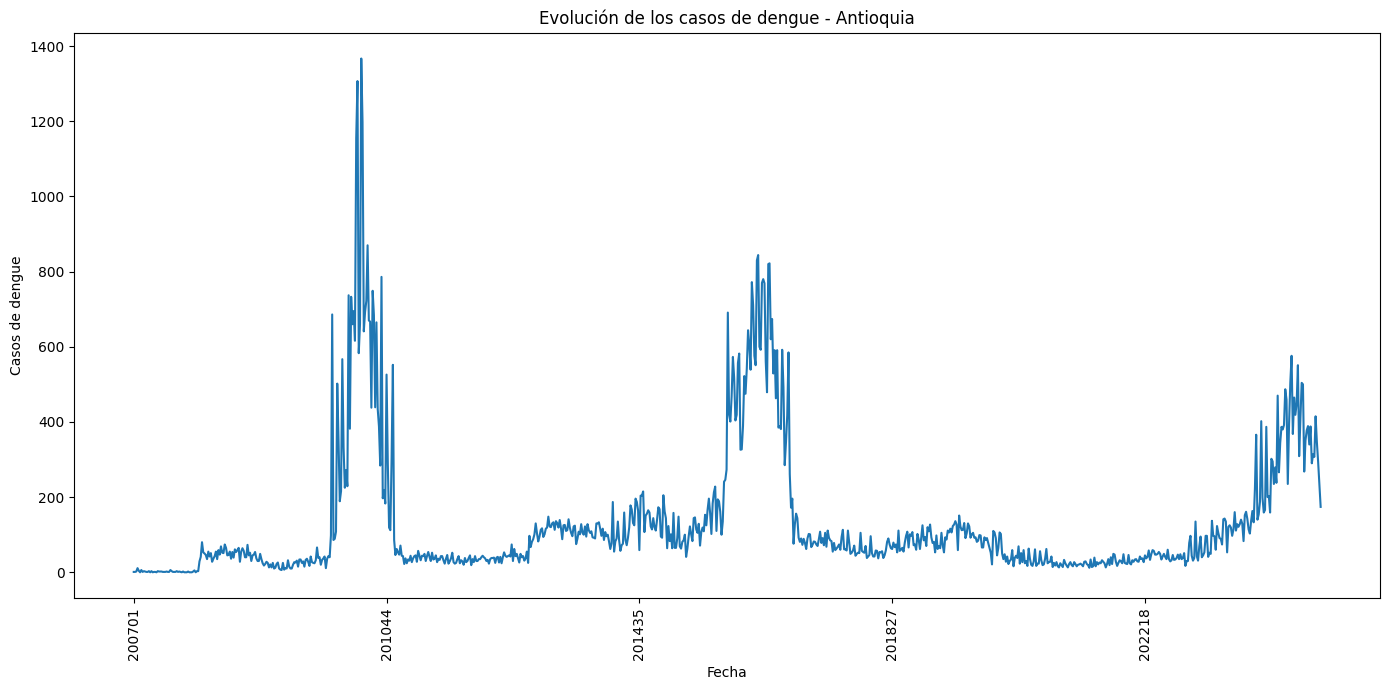

In [10]:
departamento = 'Antioquia'

# Filtrar, sumar por fecha y graficar, sin guardar otro DataFrame
ax = (
    df.loc[df['departamento'] == departamento]
      .groupby('fecha')['casos_dengue']
      .sum()
      .plot(figsize=(14, 7))
)

ax.set_xlabel('Fecha')
ax.set_ylabel('Casos de dengue')
ax.set_title(f'Evolución de los casos de dengue - {departamento}')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
import plotly.express as px

departamento = 'Antioquia'

serie = (
    df.loc[df['departamento'] == departamento]
      .groupby('fecha', as_index=False)['casos_dengue']
      .sum()
)

fig = px.line(
    serie, x='fecha', y='casos_dengue',
    title=f'Evolución de los casos de dengue - {departamento}',
    labels={'fecha': 'Fecha', 'casos_dengue': 'Casos de dengue'},
)

fig.update_traces(hovertemplate='%{x|%d %b %Y}<br>Casos: %{y:,}<extra></extra>')
fig.update_xaxes(tickangle=-90, rangeslider_visible=True)
fig.update_layout(width=1200, height=600, hovermode='x unified', template='plotly_white')
fig.show()

In [12]:
departamento = 'Antioquia'

serie = (
    df.loc[df['departamento'] == departamento]
      .assign(semana_inicio=lambda d: pd.to_datetime(d['semana_inicio']))
      .groupby('semana_inicio', as_index=False)
      .agg(casos_dengue=('casos_dengue', 'sum'), precip=('precip_chirps_mm', 'mean'))
)

fig = make_subplots(specs=[[{'secondary_y': True}]])

fig.add_trace(go.Bar(x=serie['semana_inicio'], y=serie['precip'], name='Precipitación (mm)',
                     marker_color='rgba(84,187,219,0.5)',
                     hovertemplate='Precipitación: %{y:.1f} mm<extra></extra>'),
              secondary_y=True)

fig.add_trace(go.Scatter(x=serie['semana_inicio'], y=serie['casos_dengue'], name='Casos de dengue',
                         mode='lines', line=dict(color='#C0392B', width=2),
                         hovertemplate='Casos: %{y:,}<extra></extra>'),
              secondary_y=False)

fig.update_yaxes(title_text='Casos de dengue', secondary_y=False)
fig.update_yaxes(title_text='Precipitación (mm)', secondary_y=True, showgrid=False)
fig.update_xaxes(title_text='Fecha', tickangle=-90, rangeslider_visible=True, hoverformat='%d %b %Y')
fig.update_layout(title=f'Casos de dengue y precipitación - {departamento}',
                  width=1200, height=600, hovermode='x unified', template='plotly_white',
                  legend=dict(orientation='h', y=1.08, x=0), bargap=0)
fig.show()

<Figure size 1400x700 with 0 Axes>

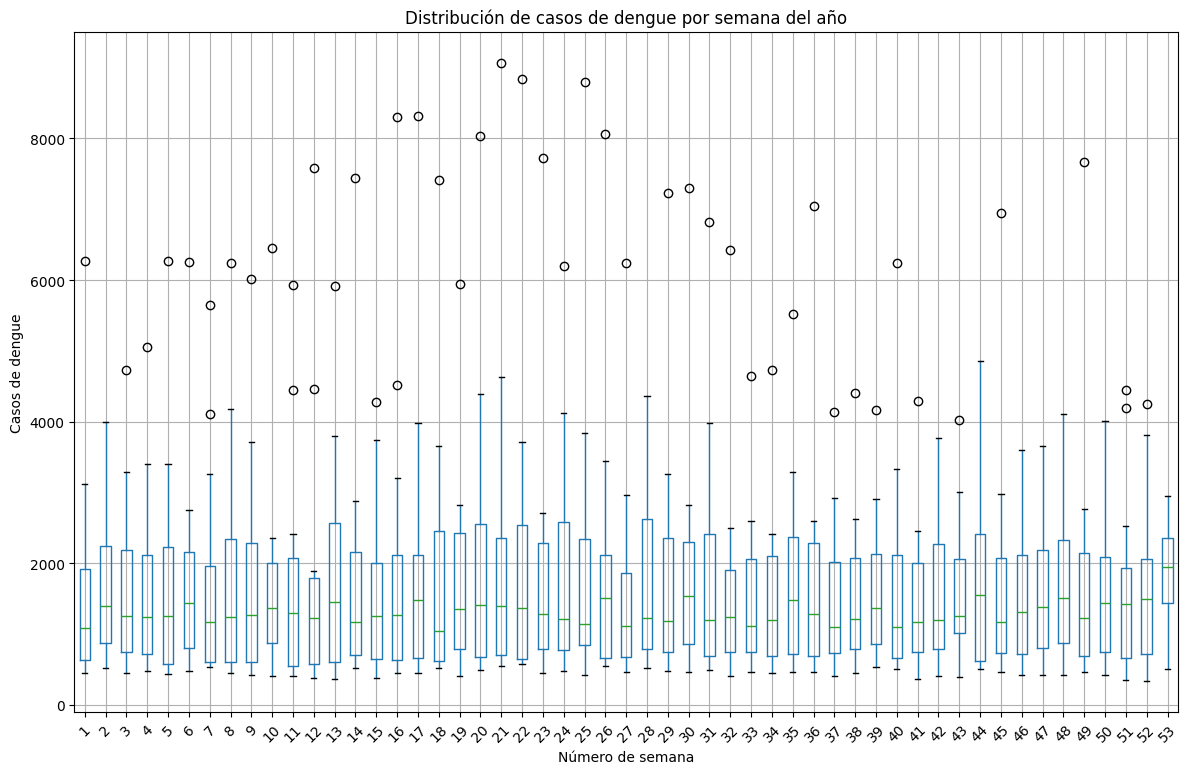

In [13]:
dengue_by_week = df.groupby(['fecha'])['casos_dengue'].sum().reset_index()
dengue_by_week.columns = ['fecha', 'casos_dengue']


dengue_by_week['week'] = dengue_by_week['fecha'].str[4:].astype(int)

# Group by week number and create boxplots
plt.figure(figsize=(14, 7))
dengue_by_week.boxplot(column='casos_dengue', by='week', figsize=(12, 8))
plt.title('Distribución de casos de dengue por semana del año')
plt.xlabel('Número de semana')
plt.ylabel('Casos de dengue')
plt.suptitle('') # Remove the default boxplot title
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [14]:
df['departamento'].unique()

array(['Amazonas', 'Antioquia', 'Arauca', 'Atlantico', 'Bolivar',
       'Boyaca', 'Caldas', 'Caqueta', 'Casanare', 'Cauca', 'Cesar',
       'Choco', 'Cordoba', 'Cundinamarca', 'Guainia', 'Guajira',
       'Guaviare', 'Huila', 'Magdalena', 'Meta', 'Narino',
       'Norte De Santander', 'Putumayo', 'Quindio', 'Risaralda',
       'Santander', 'Sucre', 'Tolima', 'Valle Del Cauca', 'Vaupes',
       'Vichada'], dtype=object)

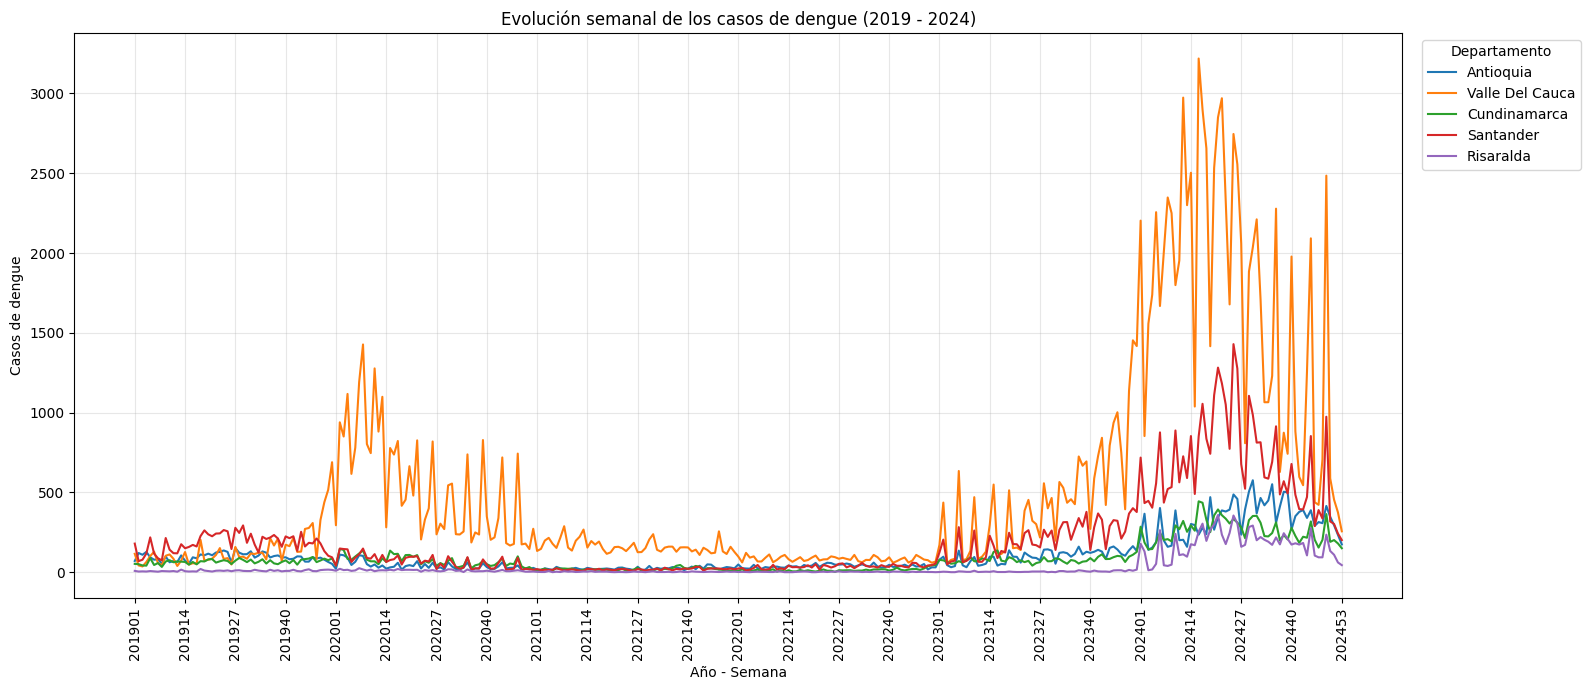

In [15]:
# Departamentos que quieres comparar
departamentos = [
    'Antioquia',
    'Valle Del Cauca',
    'Cundinamarca',
    'Santander',
    'Risaralda'
]

# Identificar los últimos 6 años disponibles en la base
anio_final = df['anio'].max()
anio_inicial = anio_final - 5

# Crear figura
plt.figure(figsize=(16, 7))

# Graficar cada departamento
for departamento in departamentos:

    filtro = (
        (df['departamento'] == departamento) &
        (df['anio'].between(anio_inicial, anio_final))
    )

    plt.plot(
        df.loc[filtro, 'fecha'],
        df.loc[filtro, 'casos_dengue'],
        label=departamento
    )

# Etiquetas
plt.xlabel('Año - Semana')
plt.ylabel('Casos de dengue')

plt.title(
    f'Evolución semanal de los casos de dengue '
    f'({anio_inicial} - {anio_final})'
)

# Mostrar una etiqueta aproximadamente cada 13 semanas
# para evitar saturar el eje X
n_semanas = len(
    df.loc[
        (df['departamento'] == departamentos[0]) &
        (df['anio'].between(anio_inicial, anio_final))
    ]
)

plt.xticks(
    np.arange(0, n_semanas, 13),
    rotation=90
)

# Leyenda con nombres de departamentos
plt.legend(
    title='Departamento',
    loc='upper left',
    bbox_to_anchor=(1.01, 1)
)

# Cuadrícula
plt.grid(alpha=0.3)

# Ajustar espacios
plt.tight_layout()

# Mostrar gráfica
plt.show()

In [16]:
dep = df[df['departamento'] == 'Antioquia']
tabla = dep.pivot_table(index='anio', columns='semana', values='casos_dengue', aggfunc='sum')
px.imshow(tabla, aspect='auto', color_continuous_scale='Reds',
          labels=dict(x='Semana epidemiológica', y='Año', color='Casos'),
          title='Casos de dengue por año y semana - Antioquia').show()

## Parámetros

In [17]:
SEQUENCE_LENGTH = 5
TARGET_COLUMN = 'casos_dengue'
GROUP_COLUMN = 'id_departamento'

## División temporal train/val

In [18]:
# Ordenar datos
df = df.sort_values(by=[GROUP_COLUMN, 'anio', 'semana'])
features_cols_ini = df.columns.difference(['anio', 'semana', TARGET_COLUMN, GROUP_COLUMN, 'ID', 'fecha', 
                                           'departamento', 'semana_fin', 'semana_inicio'])

In [19]:
features_cols_ini

Index(['evapotranspiracion_mm', 'humedad_suelo_capa1', 'precip_chirps_mm',
       'presion_superficial_hPa', 'punto_rocio_C', 'radiacion_solar_MJ_m2',
       'temp_max_C', 'temp_media_C', 'temp_min_C', 'viento_dir_grados',
       'viento_vel_m_s'],
      dtype='object')

In [20]:
df.anio.value_counts(1).sort_index().cumsum()

anio
2007    0.056383
2008    0.111702
2009    0.167021
2010    0.222340
2011    0.277660
2012    0.334043
2013    0.389362
2014    0.444681
2015    0.500000
2016    0.555319
2017    0.610638
2018    0.667021
2019    0.722340
2020    0.777660
2021    0.832979
2022    0.888298
2023    0.943617
2024    1.000000
Name: proportion, dtype: float64

In [21]:
train_df = df[df.anio < 2024].copy()
val_df = df[df.anio >= 2024].copy()

In [22]:
train_df.tail()

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
29082,32_2023_48,Vichada,32,2023,2023-11-27,2023-12-03,48,12.943423,27.520816,32.844358,23.428280,22.443079,0.357918,30.863436,143.977326,1.758507,76.523878,995.565234,2,202348
29083,32_2023_49,Vichada,32,2023,2023-12-04,2023-12-10,49,15.205700,27.690956,33.169631,23.846997,22.422405,0.313243,25.818123,130.392648,1.241481,76.135597,995.256790,1,202349
29084,32_2023_50,Vichada,32,2023,2023-12-11,2023-12-17,50,15.454294,28.049819,33.151653,23.982445,23.215261,0.343011,26.534052,130.691846,0.917934,107.449879,993.431770,9,202350
29085,32_2023_51,Vichada,32,2023,2023-12-18,2023-12-24,51,25.664735,28.264196,34.203594,23.886373,23.474406,0.336285,25.579412,131.398038,0.577730,186.463067,994.036218,4,202351
29086,32_2023_52,Vichada,32,2023,2023-12-25,2023-12-31,52,41.413875,27.112742,32.589353,23.680738,24.120444,0.413396,26.179934,119.617234,0.190251,195.734258,996.717116,1,202352


In [23]:
val_df.head()

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
887,1_2024_1,Amazonas,1,2024,2024-01-01,2024-01-07,1,56.148771,26.947276,32.878578,23.234654,24.183290,0.417890,30.855669,132.278672,0.657530,31.779005,993.681128,17,202401
888,1_2024_2,Amazonas,1,2024,2024-01-08,2024-01-14,2,72.886272,26.361571,32.411033,23.129962,24.030408,0.418378,28.706415,120.327924,0.387789,45.477396,993.957604,7,202402
889,1_2024_3,Amazonas,1,2024,2024-01-15,2024-01-21,3,62.543590,25.930666,31.883862,23.111994,24.235268,0.432541,26.571811,110.865819,0.249771,225.761299,994.662940,12,202403
890,1_2024_4,Amazonas,1,2024,2024-01-22,2024-01-28,4,53.469921,26.881898,32.663460,23.732803,24.116671,0.417669,29.634027,123.370407,0.575921,228.948870,994.590144,15,202404
891,1_2024_5,Amazonas,1,2024,2024-01-29,2024-02-04,5,69.456114,26.462840,32.475856,23.354846,24.444028,0.415683,27.821203,115.397630,0.547949,322.527965,994.081308,22,202405


# Estandarizar

In [24]:
features_cols = features_cols_ini.copy()
scaler = StandardScaler().fit(train_df[features_cols])
train_df[features_cols] = scaler.transform(train_df[features_cols])
val_df[features_cols] = scaler.transform(val_df[features_cols])

In [25]:
train_df.tail()

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
29082,32_2023_48,Vichada,32,2023,2023-11-27,2023-12-03,48,-1.031402,1.322262,1.267648,1.147741,0.813557,-0.881746,1.768087,1.265130,1.306769,-1.422457,0.990451,2,202348
29083,32_2023_49,Vichada,32,2023,2023-12-04,2023-12-10,49,-0.965034,1.367160,1.352159,1.250241,0.808162,-1.602551,0.498932,0.558189,0.637618,-1.428135,0.986035,1,202349
29084,32_2023_50,Vichada,32,2023,2023-12-11,2023-12-17,50,-0.957741,1.461858,1.347488,1.283398,1.015050,-1.122260,0.679025,0.573759,0.218873,-0.970205,0.959911,9,202350
29085,32_2023_51,Vichada,32,2023,2023-12-18,2023-12-24,51,-0.658199,1.518429,1.620796,1.259880,1.082672,-1.230775,0.438884,0.610509,-0.221430,0.185259,0.968563,4,202351
29086,32_2023_52,Vichada,32,2023,2023-12-25,2023-12-31,52,-0.196169,1.214578,1.201394,1.209541,1.251249,0.013387,0.589946,-0.002559,-0.722917,0.320838,1.006939,1,202352


In [26]:
val_df.head()

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
887,1_2024_1,Amazonas,1,2024,2024-01-01,2024-01-07,1,0.236106,1.170914,1.276539,1.100342,1.267648,0.085893,1.766133,0.656337,-0.118150,-2.076792,0.963480,17,202401
888,1_2024_2,Amazonas,1,2024,2024-01-08,2024-01-14,2,0.727131,1.016355,1.155064,1.074714,1.227755,0.093772,1.225485,0.034425,-0.467257,-1.876471,0.967438,7,202402
889,1_2024_3,Amazonas,1,2024,2024-01-15,2024-01-21,3,0.423710,0.902646,1.018098,1.070315,1.281211,0.322289,0.688523,-0.457979,-0.645884,0.759944,0.977535,12,202403
890,1_2024_4,Amazonas,1,2024,2024-01-22,2024-01-28,4,0.157517,1.153661,1.220648,1.222286,1.250264,0.082319,1.458827,0.192754,-0.223771,0.806558,0.976492,15,202404
891,1_2024_5,Amazonas,1,2024,2024-01-29,2024-02-04,5,0.626502,1.043079,1.171906,1.129764,1.335685,0.050290,1.002809,-0.222146,-0.259973,2.175029,0.969209,22,202405


## Estructura de los datos

In [27]:
class DengueDataset(Dataset):
    """
    Dataset personalizado para pronóstico de dengue en series de tiempo agrupadas.

    Este dataset transforma un DataFrame en un conjunto de ejemplos tipo
    ventana deslizante (sliding window), donde:

    - X = secuencia de longitud `sequence_length` con las variables de entrada
    - y = valor de la variable objetivo en el siguiente instante temporal

    Está pensado para trabajar con series temporales múltiples, agrupadas por
    `GROUP_COLUMN` (por ejemplo, un depatamento o zona identificado por `id_departamento`).

    Parámetros
    ----------
    df : pandas.DataFrame
        DataFrame ya ordenado temporalmente por grupo, año y semana.
    sequence_length : int
        Número de pasos de tiempo usados como entrada.
    is_train : bool, default=True
        Si es True, el dataset devuelve (X, y).
        Si es False, devuelve (X, id) para inferencia y submission.

    Supuestos
    ---------
    - `GROUP_COLUMN` existe en el entorno. En tu caso: 'id_bar'
    - `TARGET_COLUMN` existe en el entorno. En tu caso: 'dengue'
    - `features_cols` existe en el entorno y contiene las columnas predictoras
    - El DataFrame ya fue ordenado por [GROUP_COLUMN, 'anio', 'semana']

    Notas
    -----
    - Esta versión aplana la secuencia con `.flatten()`.
      Eso funciona bien para una red densa (MLP/NN).
    - Si vas a usar LSTM, GRU o RNN, lo ideal es NO usar `.flatten()`,
      sino mantener la forma [sequence_length, n_features].
    """

    def __init__(self, df, sequence_length, is_train=True):
        """
        Construye las secuencias del dataset.

        Recorre cada grupo temporal de manera independiente y genera ejemplos
        usando una ventana deslizante.

        Ejemplo con sequence_length = 3:
            semanas:   t1   t2   t3   t4
            entrada X: [t1, t2, t3]
            salida y:               t4
        """
        self.sequence_length = sequence_length
        self.is_train = is_train
        self.data = []

        # Agrupar por serie temporal independiente
        grouped = df.groupby(GROUP_COLUMN)

        for group_id, group in grouped:
            # Reiniciar índice para recorrer la serie desde 0 hasta n-1
            group = group.reset_index(drop=True)

            # Solo se pueden formar ventanas si el grupo tiene más registros
            # que la longitud de secuencia
            if len(group) > sequence_length:

                # Crear ventanas deslizantes
                for i in range(len(group) - sequence_length):

                    # Tomar las features desde i hasta i + sequence_length - 1
                    # y aplanarlas en un vector 1D
                    seq_x = group.loc[
                        i:i + sequence_length - 1,
                        features_cols
                    ].values.flatten()

                    if self.is_train:
                        # En entrenamiento, la etiqueta es el valor de dengue
                        # en el siguiente paso temporal
                        seq_y = group.loc[i + sequence_length, TARGET_COLUMN]

                        # Guardar par (X, y)
                        self.data.append((seq_x, seq_y))
                    else:
                        # En inferencia no conocemos y; guardamos el id del
                        # registro objetivo para reconstruir la predicción
                        seq_id = group.loc[i + sequence_length, 'ID']

                        # Guardar par (X, id)
                        self.data.append((seq_x, seq_id))

    def __len__(self):
        """
        Retorna el número total de secuencias generadas.
        """
        return len(self.data)

    def __getitem__(self, idx):
        """
        Devuelve un ejemplo del dataset.

        Retorna
        -------
        Si is_train=True:
            (torch.FloatTensor, torch.FloatTensor)
            -> (X, y)

        Si is_train=False:
            (torch.FloatTensor, str)
            -> (X, id)
        """
        if self.is_train:
            x, y = self.data[idx]
            return (
                torch.tensor(x, dtype=torch.float32),
                torch.tensor(y, dtype=torch.float32)
            )
        else:
            x, seq_id = self.data[idx]
            return (
                torch.tensor(x, dtype=torch.float32),
                seq_id
            )

In [28]:
# Diagnóstico: ¿hay NaN en las features o en el target?
print("NaN por columna en df completo:")
print(df[list(features_cols_ini) + [TARGET_COLUMN]].isna().sum()[lambda s: s > 0])

NaN por columna en df completo:
Series([], dtype: int64)


## Ejemplo de la clase DengueDataset

In [29]:
# Crear dataset de entrenamiento (10 semanas de un solo departamento)
data = train_df[train_df.id_departamento == 1].head(10).copy()
SEQUENCE_LENGTH_p = 5
dataset_train = DengueDataset(data, SEQUENCE_LENGTH_p, is_train=True)

L = SEQUENCE_LENGTH_p
n_feat = len(features_cols)
datos = data.reset_index(drop=True)
etiq = lambda p: f"{datos.loc[p, 'anio']}-S{int(datos.loc[p, 'semana']):02d}"

print("=" * 75)
print(f"DATOS DE ENTRADA: {len(datos)} semanas de {datos.loc[0, 'departamento']}")
print("=" * 75)
print(datos[['anio', 'semana', TARGET_COLUMN]].rename_axis('pos').to_string())

print(f"\nSEQUENCE_LENGTH = {L} → cada ejemplo mira {L} semanas hacia atrás para predecir la siguiente.")
print(f"Cada X tiene {L} semanas × {n_feat} variables = {L * n_feat} valores (aplanados para el MLP).")
print(f"Secuencias posibles: {len(datos)} semanas - {L} = {len(datos) - L}  |  En el dataset: {len(dataset_train)}")

for i in range(len(dataset_train)):
    X, Y = dataset_train[i]
    pos_x, pos_y = list(range(i, i + L)), i + L

    print("\n" + "-" * 75)
    print(f"EJEMPLO {i+1}: semanas {etiq(pos_x[0])} a {etiq(pos_x[-1])} → predice {etiq(pos_y)}")
    print(f"  X: tensor de {tuple(X.shape)} → se ve así al 'desaplanarlo' ({L} semanas × {n_feat} variables, estandarizadas):")
    X_tabla = pd.DataFrame(X.numpy().reshape(L, n_feat), columns=features_cols,
                           index=[etiq(p) for p in pos_x])
    print(X_tabla.round(2).to_string())
    print(f"  Y: {Y.item():.0f} casos  (valor real en {etiq(pos_y)}: {datos.loc[pos_y, TARGET_COLUMN]:.0f}) "
          f"{'✅' if np.isclose(Y.item(), datos.loc[pos_y, TARGET_COLUMN]) else '⚠️'}")

DATOS DE ENTRADA: 10 semanas de Amazonas
     anio  semana  casos_dengue
pos                            
0    2007       1             0
1    2007       2             0
2    2007       3             0
3    2007       4             1
4    2007       5             1
5    2007       6             0
6    2007       7             0
7    2007       8             1
8    2007       9             1
9    2007      10             0

SEQUENCE_LENGTH = 5 → cada ejemplo mira 5 semanas hacia atrás para predecir la siguiente.
Cada X tiene 5 semanas × 11 variables = 55 valores (aplanados para el MLP).
Secuencias posibles: 10 semanas - 5 = 5  |  En el dataset: 5

---------------------------------------------------------------------------
EJEMPLO 1: semanas 2007-S01 a 2007-S05 → predice 2007-S06
  X: tensor de (55,) → se ve así al 'desaplanarlo' (5 semanas × 11 variables, estandarizadas):
          evapotranspiracion_mm  humedad_suelo_capa1  precip_chirps_mm  presion_superficial_hPa  punto_rocio_C  radia

# Modelo MLP

In [30]:
# Crear loaders
train_loader = DataLoader(DengueDataset(train_df, SEQUENCE_LENGTH), batch_size=32, shuffle=True)
val_loader = DataLoader(DengueDataset(val_df, SEQUENCE_LENGTH), batch_size=32, shuffle=False)

In [31]:
class SimpleMLP(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super(SimpleMLP, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1),
            nn.ReLU()
        )

    def forward(self, x):
        return self.fc(x).squeeze()

# Entrenamiento

In [32]:
features_cols = features_cols_ini.copy()
input_size = len(features_cols) * SEQUENCE_LENGTH
model = SimpleMLP(input_size).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [33]:
features_cols

Index(['evapotranspiracion_mm', 'humedad_suelo_capa1', 'precip_chirps_mm',
       'presion_superficial_hPa', 'punto_rocio_C', 'radiacion_solar_MJ_m2',
       'temp_max_C', 'temp_media_C', 'temp_min_C', 'viento_dir_grados',
       'viento_vel_m_s'],
      dtype='object')

In [34]:
len(features_cols)

11

In [35]:
input_size

55

In [36]:
for epoch in range(20):
    """
    Loop principal de entrenamiento.
    Recorre el dataset completo 20 veces (20 epochs).
    """

    # =========================
    # 🔹 FASE DE ENTRENAMIENTO
    # =========================
    model.train()  # Activa modo entrenamiento (importante para dropout, batchnorm)
    train_loss = 0  # Acumulador de pérdida de entrenamiento

    for x_batch, y_batch in train_loader:
        """
        Itera sobre los datos de entrenamiento en mini-batches.
        """

        # Mover datos a GPU o CPU
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)

        # Reiniciar gradientes (muy importante en PyTorch)
        optimizer.zero_grad()

        # Forward pass: predicción del modelo
        predictions = model(x_batch)

        # Calcular pérdida (error entre predicción y valor real)
        loss = criterion(predictions, y_batch)

        # Backpropagation: cálculo de gradientes
        loss.backward()

        # Actualizar pesos del modelo
        optimizer.step()

        # Acumular pérdida
        train_loss += loss.item()

    # =========================
    # 🔹 FASE DE VALIDACIÓN
    # =========================
    model.eval()  # Modo evaluación (desactiva dropout, etc.)
    val_loss = 0  # Acumulador de pérdida de validación

    with torch.no_grad():  # No calcula gradientes → más rápido y menos memoria
        for x_batch, y_batch in val_loader:

            # Mover datos a dispositivo
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)

            # Forward pass (sin entrenamiento)
            predictions = model(x_batch)

            # Calcular pérdida
            loss = criterion(predictions, y_batch)

            # Acumular pérdida
            val_loss += loss.item()

    # =========================
    # 🔹 LOG DE RESULTADOS
    # =========================
    print(
        f'Epoch {epoch+1}/20 | '
        f'Train MSE: {train_loss/len(train_loader):.4f} | '
        f'Val MSE: {val_loss/len(val_loader):.4f}'
    )

Epoch 1/20 | Train MSE: 7838.1423 | Val MSE: 147009.2188
Epoch 2/20 | Train MSE: 6664.6566 | Val MSE: 140690.0162
Epoch 3/20 | Train MSE: 6131.9286 | Val MSE: 137033.9826
Epoch 4/20 | Train MSE: 5866.8342 | Val MSE: 132523.8752
Epoch 5/20 | Train MSE: 5704.5690 | Val MSE: 130160.4730
Epoch 6/20 | Train MSE: 5600.9944 | Val MSE: 128804.8541
Epoch 7/20 | Train MSE: 5525.2989 | Val MSE: 128265.1382
Epoch 8/20 | Train MSE: 5475.0609 | Val MSE: 127609.9810
Epoch 9/20 | Train MSE: 5431.1008 | Val MSE: 126092.1691
Epoch 10/20 | Train MSE: 5395.2053 | Val MSE: 125330.6770
Epoch 11/20 | Train MSE: 5368.8164 | Val MSE: 125176.4923
Epoch 12/20 | Train MSE: 5346.4877 | Val MSE: 124961.0202
Epoch 13/20 | Train MSE: 5323.1632 | Val MSE: 124415.6592
Epoch 14/20 | Train MSE: 5304.2261 | Val MSE: 122420.6189
Epoch 15/20 | Train MSE: 5302.0049 | Val MSE: 122900.1773
Epoch 16/20 | Train MSE: 5270.1124 | Val MSE: 122044.9714
Epoch 17/20 | Train MSE: 5251.9033 | Val MSE: 123362.8358
Epoch 18/20 | Train MSE

In [37]:
# Guardar modelo entrenado
torch.save(model.state_dict(), 'dengue_model.pth')

# Submission

In [38]:
# Cargar datos nuevos y preparar submission
features_cols = features_cols_ini.copy()
df_test = pd.read_parquet('/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn/test.parquet')
print(df_test['id_departamento'].unique())
df_test = df_test.sort_values(by=[GROUP_COLUMN, 'anio', 'semana'])
df_test[features_cols] = scaler.transform(df_test[features_cols])
df_test.head()

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 27 28 29 30 31 32]


,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa
0,1_2025_1,Amazonas,1,2025,2025-01-06,2025-01-12,1,-0.454581,0.952386,0.979678,1.008567,1.215003,0.319404,1.600408,0.412706,-0.370733,-1.909281,0.954891
1,1_2025_2,Amazonas,1,2025,2025-01-13,2025-01-19,2,-0.847202,1.194168,1.321639,0.845343,0.575193,-0.467107,2.944673,1.842099,0.546765,-1.684437,0.962766
2,1_2025_3,Amazonas,1,2025,2025-01-20,2025-01-26,3,-0.581641,0.945079,1.421898,0.893080,0.828468,-0.598761,1.468045,0.421638,-0.072510,-1.927619,0.979067
3,1_2025_4,Amazonas,1,2025,2025-01-27,2025-02-02,4,0.794484,0.716780,0.763572,0.910585,1.138293,0.392672,0.640850,-0.438865,-0.767354,-0.786928,0.969404
4,1_2025_5,Amazonas,1,2025,2025-02-03,2025-02-09,5,0.433812,0.618471,0.849374,0.872222,1.107301,0.417625,-0.360930,-1.641996,-0.468459,1.843896,0.956139


In [39]:
# Agregar últimas SEQUENCE_LENGTH filas del entrenamiento a cada grupo de test
historical_sequences = val_df.groupby(GROUP_COLUMN).tail(SEQUENCE_LENGTH)
df_test_extended = pd.concat([historical_sequences, df_test], ignore_index=True)
df_test_extended = df_test_extended.sort_values(by=[GROUP_COLUMN, 'anio', 'semana']).reset_index(drop=True)

In [40]:
df_test_extended.head(10)

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
0,1_2024_49,Amazonas,1,2024,2024-12-02,2024-12-08,49,0.419239,0.978068,1.184375,1.076654,1.314979,0.249094,0.879902,-0.314881,-0.178941,-1.698710,0.942296,15.0,202449
1,1_2024_50,Amazonas,1,2024,2024-12-09,2024-12-15,50,-0.099430,0.849810,1.002900,0.988997,1.173315,0.283219,0.362700,-0.683877,-0.568607,-0.810044,0.946889,10.0,202450
2,1_2024_51,Amazonas,1,2024,2024-12-16,2024-12-22,51,1.283424,0.768619,1.035202,0.985299,1.205468,0.410859,0.162720,-0.927615,-0.791855,-0.207833,0.972757,7.0,202451
3,1_2024_52,Amazonas,1,2024,2024-12-23,2024-12-29,52,0.426737,0.748430,0.838445,0.978617,1.175776,0.432162,0.386519,-0.871683,-0.714849,0.436378,0.967250,10.0,202452
4,1_2024_53,Amazonas,1,2024,2024-12-30,2025-01-05,53,0.661033,0.724390,0.836484,0.937701,1.132267,0.417210,0.392087,-0.630783,-0.748775,-1.004304,0.963178,8.0,202453
5,1_2025_1,Amazonas,1,2025,2025-01-06,2025-01-12,1,-0.454581,0.952386,0.979678,1.008567,1.215003,0.319404,1.600408,0.412706,-0.370733,-1.909281,0.954891,NaN,NaN
6,1_2025_2,Amazonas,1,2025,2025-01-13,2025-01-19,2,-0.847202,1.194168,1.321639,0.845343,0.575193,-0.467107,2.944673,1.842099,0.546765,-1.684437,0.962766,NaN,NaN
7,1_2025_3,Amazonas,1,2025,2025-01-20,2025-01-26,3,-0.581641,0.945079,1.421898,0.893080,0.828468,-0.598761,1.468045,0.421638,-0.072510,-1.927619,0.979067,NaN,NaN
8,1_2025_4,Amazonas,1,2025,2025-01-27,2025-02-02,4,0.794484,0.716780,0.763572,0.910585,1.138293,0.392672,0.640850,-0.438865,-0.767354,-0.786928,0.969404,NaN,NaN
9,1_2025_5,Amazonas,1,2025,2025-02-03,2025-02-09,5,0.433812,0.618471,0.849374,0.872222,1.107301,0.417625,-0.360930,-1.641996,-0.468459,1.843896,0.956139,NaN,NaN


In [41]:
# Crear loader para predicción
test_loader = DataLoader(DengueDataset(df_test_extended, SEQUENCE_LENGTH, is_train=False), batch_size=32, shuffle=False)

In [42]:
# Generar predicciones
model.eval()
predictions = []
ids = []

with torch.no_grad():
    for x_batch, id_batch in test_loader:
        x_batch = x_batch.to(device)
        preds = model(x_batch).cpu().numpy()
        predictions.extend(preds)
        ids.extend(id_batch)

In [43]:
len(ids)

1612

In [44]:
# Preparar submission con todos los registros
df_submission = pd.DataFrame({'id': ids, 'dengue': predictions})

# Exportar a CSV
df_submission.to_csv('submission_dengue.csv', index=False)
print(f'Submission guardado en submission.csv, con {len(df_submission)} predicciones.')

Submission guardado en submission.csv, con 1612 predicciones.


In [45]:
df_submission

,id,dengue
0,1_2025_1,0.000000
1,1_2025_2,0.000000
2,1_2025_3,0.000000
3,1_2025_4,0.000000
4,1_2025_5,0.000000
...,...,...
1607,32_2025_48,35.748695
1608,32_2025_49,38.733116
1609,32_2025_50,44.931252
1610,32_2025_51,44.604126


# TCN

In [46]:
class DengueTCNDataset(Dataset):
    """
    Igual que DengueDataset pero sin .flatten().
    Devuelve X con shape [sequence_length, n_features]
    para que el TCN pueda operar sobre la dimensión temporal.
    """
    def __init__(self, df, sequence_length, is_train=True):
        self.sequence_length = sequence_length
        self.is_train = is_train
        self.data = []

        grouped = df.groupby(GROUP_COLUMN)

        for group_id, group in grouped:
            group = group.reset_index(drop=True)
            if len(group) > sequence_length:
                for i in range(len(group) - sequence_length):
                    seq_x = group.loc[
                        i:i + sequence_length - 1,
                        features_cols
                    ].values.astype(np.float32)

                    if self.is_train:
                        seq_y = np.float32(group.loc[i + sequence_length, TARGET_COLUMN])
                        self.data.append((seq_x, seq_y))
                    else:
                        seq_id = group.loc[i + sequence_length, 'ID']
                        self.data.append((seq_x, seq_id))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        seq_x, label = self.data[idx]
        if self.is_train:
            return torch.tensor(seq_x), torch.tensor(label)
        else:
            return torch.tensor(seq_x), label

In [47]:
class CausalConv1d(nn.Module):
    """
    Convolución 1-D causal con dilatación.
    Añade padding a la IZQUIERDA para que la salida solo dependa
    del pasado → no hay fuga de información del futuro.
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        # padding = (kernel_size - 1) * dilation garantiza misma longitud de salida
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels, out_channels,
            kernel_size=kernel_size,
            dilation=dilation,
            padding=self.padding
        )

    def forward(self, x):
        # Recortar el padding derecho para preservar causalidad
        out = self.conv(x)
        return out[:, :, :-self.padding] if self.padding > 0 else out


class TCNBlock(nn.Module):
    """
    Bloque residual TCN:
      CausalConv → GroupNorm → ReLU → Dropout
      CausalConv → GroupNorm → ReLU → Dropout
      + conexión residual (con 1x1 conv si los canales cambian)
 
    Nota: se usa GroupNorm en lugar de LayerNorm porque opera sobre
    tensores [batch, channels, seq_len] sin necesidad de transponer.
    num_groups=1 equivale a LayerNorm sobre los canales (InstanceNorm).
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            CausalConv1d(in_channels, out_channels, kernel_size, dilation),
            nn.GroupNorm(num_groups=1, num_channels=out_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
            CausalConv1d(out_channels, out_channels, kernel_size, dilation),
            nn.GroupNorm(num_groups=1, num_channels=out_channels),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels else nn.Identity()
        )
        self.relu = nn.ReLU()
 
    def forward(self, x):
        out = self.net(x)
        return self.relu(out + self.residual(x))


class TCN(nn.Module):
    """
    Red TCN completa.

    Parámetros
    ----------
    input_size   : número de features (n_features)
    num_channels : lista con el nº de filtros por capa, e.g. [32, 32, 64, 64]
                   len(num_channels) = profundidad de la red
    kernel_size  : tamaño del kernel de convolución
    dropout      : tasa de dropout
    """
    def __init__(self, input_size, num_channels, kernel_size=3, dropout=0.1):
        super().__init__()
        layers = []
        num_levels = len(num_channels)

        for i in range(num_levels):
            dilation = 2 ** i 
            in_ch  = input_size if i == 0 else num_channels[i - 1]
            out_ch = num_channels[i]
            layers.append(TCNBlock(in_ch, out_ch, kernel_size, dilation, dropout))

        self.network = nn.Sequential(*layers)
        self.fc = nn.Linear(num_channels[-1], 1)   # capa de salida

    def forward(self, x):
        # x entra como [batch, seq_len, features]
        # Conv1d espera [batch, channels, seq_len] → transponemos
        x = x.transpose(1, 2)            # → [batch, features, seq_len]
        out = self.network(x)             # → [batch, num_channels[-1], seq_len]
        out = out[:, :, -1]               # último paso temporal → [batch, channels]
        return self.fc(out).squeeze(-1)   # → [batch]

In [48]:
# 3. DATALOADERS

train_loader_tcn = DataLoader(
    DengueTCNDataset(train_df, SEQUENCE_LENGTH, is_train=True),
    batch_size=64,
    shuffle=True
)
val_loader_tcn = DataLoader(
    DengueTCNDataset(val_df, SEQUENCE_LENGTH, is_train=True),
    batch_size=64,
    shuffle=False
)

In [49]:
# ──────────────────────────────────────────────────────────────
# 4. CONFIGURACIÓN DEL MODELO
# ──────────────────────────────────────────────────────────────

n_features   = len(features_cols)

# num_channels define profundidad y ancho de la red:
#   - cada elemento = nº de filtros en esa capa
#   - la dilatación se duplica automáticamente: 1, 2, 4, 8, ...
NUM_CHANNELS = [32, 32, 64, 64]   # 4 capas, campo receptivo amplio
KERNEL_SIZE  = 3
DROPOUT      = 0.1
N_EPOCHS     = 30
LR           = 1e-3

reset_seed()

model_tcn = TCN(
    input_size   = n_features,
    num_channels = NUM_CHANNELS,
    kernel_size  = KERNEL_SIZE,
    dropout      = DROPOUT
).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model_tcn.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=5, factor=0.5
)

print(f"Parámetros entrenables: {sum(p.numel() for p in model_tcn.parameters()):,}")

Parámetros entrenables: 56,993


In [50]:
# 5. LOOP DE ENTRENAMIENTO

best_val_loss = float('inf')
best_state    = None

for epoch in range(N_EPOCHS):

    # Entrenamiento
    model_tcn.train()
    train_loss = 0.0

    for x_batch, y_batch in train_loader_tcn:
        x_batch = x_batch.to(device)           # [batch, seq_len, features]
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        preds = model_tcn(x_batch)
        loss  = criterion(preds, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model_tcn.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()
        train_loss += loss.item()

    # Validación
    model_tcn.eval()
    val_loss = 0.0

    with torch.no_grad():
        for x_batch, y_batch in val_loader_tcn:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            preds   = model_tcn(x_batch)
            val_loss += criterion(preds, y_batch).item()

    avg_train = train_loss / len(train_loader_tcn)
    avg_val   = val_loss   / len(val_loader_tcn)

    # Scheduler reduce LR si val no mejora
    scheduler.step(avg_val)

    # Guardar mejor modelo
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        best_state    = {k: v.clone() for k, v in model_tcn.state_dict().items()}

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:>3}/{N_EPOCHS} | "
              f"Train MSE: {avg_train:.4f} | "
              f"Val MSE:   {avg_val:.4f}{'  ← best' if avg_val == best_val_loss else ''}")

# Cargar los pesos del mejor checkpoint
model_tcn.load_state_dict(best_state)
print(f"\nModelo restaurado al mejor checkpoint → Val MSE: {best_val_loss:.4f}")
torch.save(best_state, 'tcn_dengue_best.pth')

Epoch   1/30 | Train MSE: 6289.4882 | Val MSE:   126777.2076  ← best
Epoch   5/30 | Train MSE: 4622.3436 | Val MSE:   107657.0591  ← best
Epoch  10/30 | Train MSE: 4272.8517 | Val MSE:   94506.8497  ← best
Epoch  15/30 | Train MSE: 3969.6209 | Val MSE:   97139.4801
Epoch  20/30 | Train MSE: 3666.3716 | Val MSE:   98940.5038
Epoch  25/30 | Train MSE: 3507.9288 | Val MSE:   88679.6410  ← best
Epoch  30/30 | Train MSE: 3424.7983 | Val MSE:   89363.3195

Modelo restaurado al mejor checkpoint → Val MSE: 86937.6088


In [51]:
df_test_extended.head(10)

,ID,departamento,id_departamento,anio,semana_inicio,semana_fin,semana,precip_chirps_mm,temp_media_C,temp_max_C,temp_min_C,punto_rocio_C,humedad_suelo_capa1,evapotranspiracion_mm,radiacion_solar_MJ_m2,viento_vel_m_s,viento_dir_grados,presion_superficial_hPa,casos_dengue,fecha
0,1_2024_49,Amazonas,1,2024,2024-12-02,2024-12-08,49,0.419239,0.978068,1.184375,1.076654,1.314979,0.249094,0.879902,-0.314881,-0.178941,-1.698710,0.942296,15.0,202449
1,1_2024_50,Amazonas,1,2024,2024-12-09,2024-12-15,50,-0.099430,0.849810,1.002900,0.988997,1.173315,0.283219,0.362700,-0.683877,-0.568607,-0.810044,0.946889,10.0,202450
2,1_2024_51,Amazonas,1,2024,2024-12-16,2024-12-22,51,1.283424,0.768619,1.035202,0.985299,1.205468,0.410859,0.162720,-0.927615,-0.791855,-0.207833,0.972757,7.0,202451
3,1_2024_52,Amazonas,1,2024,2024-12-23,2024-12-29,52,0.426737,0.748430,0.838445,0.978617,1.175776,0.432162,0.386519,-0.871683,-0.714849,0.436378,0.967250,10.0,202452
4,1_2024_53,Amazonas,1,2024,2024-12-30,2025-01-05,53,0.661033,0.724390,0.836484,0.937701,1.132267,0.417210,0.392087,-0.630783,-0.748775,-1.004304,0.963178,8.0,202453
5,1_2025_1,Amazonas,1,2025,2025-01-06,2025-01-12,1,-0.454581,0.952386,0.979678,1.008567,1.215003,0.319404,1.600408,0.412706,-0.370733,-1.909281,0.954891,NaN,NaN
6,1_2025_2,Amazonas,1,2025,2025-01-13,2025-01-19,2,-0.847202,1.194168,1.321639,0.845343,0.575193,-0.467107,2.944673,1.842099,0.546765,-1.684437,0.962766,NaN,NaN
7,1_2025_3,Amazonas,1,2025,2025-01-20,2025-01-26,3,-0.581641,0.945079,1.421898,0.893080,0.828468,-0.598761,1.468045,0.421638,-0.072510,-1.927619,0.979067,NaN,NaN
8,1_2025_4,Amazonas,1,2025,2025-01-27,2025-02-02,4,0.794484,0.716780,0.763572,0.910585,1.138293,0.392672,0.640850,-0.438865,-0.767354,-0.786928,0.969404,NaN,NaN
9,1_2025_5,Amazonas,1,2025,2025-02-03,2025-02-09,5,0.433812,0.618471,0.849374,0.872222,1.107301,0.417625,-0.360930,-1.641996,-0.468459,1.843896,0.956139,NaN,NaN


In [52]:
test_loader_tcn = DataLoader(
    DengueTCNDataset(df_test_extended, SEQUENCE_LENGTH, is_train=False),
    batch_size=64, shuffle=False
)

model_tcn.eval()
all_preds, all_ids = [], []
with torch.no_grad():
    for x_batch, id_batch in test_loader_tcn:
        x_batch = x_batch.to(device)
        preds   = model_tcn(x_batch).cpu().numpy()
        all_preds.extend(preds)
        all_ids.extend(id_batch)

In [53]:
submission = pd.DataFrame({'id': all_ids, 'dengue': all_preds})
submission['dengue'] = submission['dengue'].clip(lower=0).round().astype(int)
submission.to_csv('submission_tcn.csv', index=False)
print(submission.shape)
submission.head()

(1612, 2)


,id,dengue
0,1_2025_1,7
1,1_2025_2,12
2,1_2025_3,8
3,1_2025_4,8
4,1_2025_5,4
